# Step 2 — Getting TESS light curves: data sources, products, and how to download them

A *light curve* is a table of brightness measurements of one star over time.
TESS does not deliver light curves directly: it delivers **images**, and
several independent teams turn those images into light curves, each with its
own choices. For any given star and sector there may be zero, one or five
different light curves on the archive. This notebook explains:

- how TESS takes its data, and what the different products are;
- who makes light curves (SPOC, TESS-SPOC, QLP, ...), how they differ, and
  which to prefer for a transit search;
- how to search and download them with **lightkurve**, and what is inside the
  files (flux columns, quality flags);
- what changes when you do this for thousands of stars instead of one.

It needs an internet connection; it downloads a handful of files (a few MB
each, ~30 MB in total) into `data/walkthrough_downloads/`.

Where this step sits:

| step | what | input | output |
|---|---|---|---|
| 1 | build the target list | TESS Input Catalog | one row per star (`tic_id`, ...) |
| **2** | **download light curves** | **MAST archive** | **one raw light-curve file per star + a manifest (which file, which product, status)** |
| 3 | detrend | raw light curves | flattened light curves |
| 4 | transit search | flattened light curves | best periodic signal per star |
| 5 | vetting | search results | candidates |

Sections:

1. How TESS takes data: full-frame images and postage stamps
2. Who makes the light curves: the pipelines and their products
3. Searching the archive with lightkurve
4. Downloading, caching, and what is in the file
5. Quality flags
6. The same star, three products: which one is better for a transit search?
7. Other ways to get the data
8. Doing it for thousands of stars

In [1]:
import time
import warnings
from pathlib import Path

import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits

warnings.filterwarnings("ignore", module="lightkurve")
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

SECTOR = 104
DOWNLOAD_DIR = Path("..") / "data" / "walkthrough_downloads"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

LHS3844 = 410153553  # an M dwarf with a known transiting planet (P = 0.463 d); has SPOC 20 s, SPOC 2 min and QLP in sector 104
FAINT = 6283622  # a fainter M dwarf (Tmag 12.9) with only a QLP light curve in sector 104
EDGE = 165941376  # a Tmag 10.8 M dwarf that tess-point puts at the very edge of a CCD (row 2048) in sector 104: no light curve

## 1. How TESS takes data

TESS has four cameras, each a 2×2 mosaic of CCDs, covering a 24° × 96° strip of
sky for one **sector** of ~27 days. The cameras take 2-second exposures
continuously; the on-board computer co-adds them into two kinds of products:

| product | what | cadence (exposure time) | who gets it |
|---|---|---|---|
| **Full-frame images (FFIs)** | the whole field of view, every pixel | 30 min (2018–2020), 10 min (2020–2022), **200 s** (since Sept 2022, sector 56) | every star in the field (~millions per sector) |
| **Target pixel files (TPFs)** / postage stamps | a small cut-out (~11×11 pixels) around selected stars | **2 min** (all years), **20 s** (since sector 27, a few hundred to ~1 000 stars) | ~10 000–20 000 pre-selected targets per sector, chosen through the TESS Guest Investigator programme and the mission's own priority list |

Faster cadence means more points per transit (better transit shape, better
timing) but each point is noisier; for detecting a transit what counts is the
total number of photons collected during the transit, which is the same — as
long as the cadence is short compared with the transit (for a 1-hour transit,
200 s or shorter is fine; 30 min is not).

The **pixels are big**: 21 arcseconds. A star's light spreads over a few
pixels, and neighbouring stars' light leaks in (the *contamination* of the
target-list notebook).

## 2. Who makes the light curves

To turn pixels into a light curve, a pipeline chooses an **aperture** (the set
of pixels to sum), subtracts the **background** (sky and scattered light), and
sums the remaining flux at every cadence: this is **simple aperture photometry
(SAP)**. Then most pipelines also try to remove instrumental trends. The main
pipelines:

| author (in the archive) | made by | from | cadence | which stars | flux columns |
|---|---|---|---|---|---|
| **SPOC** | NASA Ames (Science Processing Operations Center) — the official mission pipeline | TPFs | 2 min, 20 s | pre-selected targets only | `SAP_FLUX`, **`PDCSAP_FLUX`** |
| **TESS-SPOC** | the same SPOC pipeline applied to FFIs (a "High-Level Science Product", HLSP) | FFIs | 30 min / 10 min / 200 s | up to ~160 000 stars per sector, bright ones | `SAP_FLUX`, `PDCSAP_FLUX` |
| **QLP** | MIT's Quick-Look Pipeline (HLSP) — the pipeline that finds most TESS planet candidates | FFIs | same as FFIs | down to Tmag ≈ 13.5 (fainter in recent sectors) | `SAP_FLUX`, `DET_FLUX` (QLP's own detrended flux) — older sectors: `KSPSAP_FLUX` |
| TGLC, eleanor, CDIPS, PATHOS, TASOC, ... | various teams (HLSPs) | FFIs | | specialised: faint stars (TGLC to Tmag 16), clusters, asteroseismology | various |

The key terms:

- **SAP flux**: the raw sum of the aperture pixels, background subtracted. It
  contains everything: the star's variability *and* instrument systematics.
- **PDCSAP flux** (*Presearch Data Conditioning* SAP): SPOC fits and removes
  trends that are **common to many stars on the same CCD** (pointing jitter,
  thermal drifts, scattered light), using *cotrending basis vectors*; it also
  subtracts the estimated light of neighbours in the aperture (the
  `CROWDSAP` keyword in the header) and corrects for the fraction of the
  star's light falling outside the aperture (`FLFRCSAP`). Because the
  corrections are derived from many stars, PDC removes instrumental trends
  without, in principle, removing a planet's transit — and it leaves most of
  the star's own variability in place.
- **Detrended flux** (QLP's `DET_FLUX`/`KSPSAP_FLUX`): a flux already
  high-pass-filtered by the pipeline (a spline fit). Convenient, but you
  inherit their filter choice; a search pipeline that wants to control its own
  detrending (and to treat all stars the same way) starts from SAP.

**Availability lags behind the observations**: SPOC 2-min light curves appear
on the archive ~1 month after a sector ends, QLP ~1–2 months, TESS-SPOC much
later (a year or more in recent years). For a recent sector, the realistic
choice is SPOC where it exists and QLP for everything else.

All of these live on **MAST** (the Mikulski Archive for Space Telescopes,
archive.stsci.edu), NASA's archive for TESS.

## 3. Searching the archive with lightkurve

**lightkurve** is the standard Python package for Kepler and TESS data.
`lk.search_lightcurve(target, ...)` queries MAST and returns a table of
available light curves — nothing is downloaded yet. The target can be a name
("LHS 3844"), coordinates, or `"TIC <id>"` (the unambiguous choice). Useful
filters: `sector=`, `author=` (one name or a list), `exptime=` (seconds).

All sectors and all authors for LHS 3844:

In [2]:
t0 = time.time()
sr_all = lk.search_lightcurve(f"TIC {LHS3844}")
print(f"{len(sr_all)} light curves found in {time.time() - t0:.1f} s")
summary = sr_all.table.to_pandas()
summary["sector"] = summary["mission"].str.extract(r"(\d+)").astype(int)
summary.pivot_table(index="author", columns="exptime", values="sector",
                    aggfunc=lambda s: ", ".join(map(str, sorted(set(s)))), fill_value="")

51 light curves found in 10.3 s


exptime,20.0,120.0,200.0,600.0,1800.0
author,,,,,
CDIPS,,,,,"27, 28"
GSFC-ELEANOR-LITE,,,,,1
QLP,,,"67, 68, 95, 101, 102, 103, 104","27, 28",1
SPOC,"27, 28, 67, 68, 94, 95, 101, 102, 103, 104","1, 27, 28, 67, 68, 94, 95, 101, 102, 103, 104",,,
T16,,,,,1
TARS,,,"67, 68, 94, 95","27, 28",1
TASOC,,1,,,1
TESS-SPOC,,,"67, 68","27, 28",1
TGLC,,,,,1


One star, observed in ~10 sectors since 2018, with up to five pipelines per
sector at different cadences. Now only our sector, only the three authors we
consider:

In [3]:
AUTHORS = ["SPOC", "TESS-SPOC", "QLP"]
sr = lk.search_lightcurve(f"TIC {LHS3844}", sector=SECTOR, author=AUTHORS)
sr

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 104,2026,SPOC,20,410153553,0.0
1,TESS Sector 104,2026,SPOC,120,410153553,0.0
2,TESS Sector 104,2026,QLP,200,410153553,0.0


And a typical fainter target, which was not on anyone's 2-minute target list:

In [4]:
sr_faint = lk.search_lightcurve(f"TIC {FAINT}", sector=SECTOR, author=AUTHORS)
sr_faint

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 104,2026,QLP,200,6283622,0.0


### 3.1 Choosing one product per star

For a survey we want **one** light curve per star, chosen by a fixed rule so
that the result is reproducible. A sensible preference order for a transit
search:

1. **SPOC 2 min** — the best systematics correction (PDC), real per-point
   errors, and a cadence short enough for any transit.
2. **SPOC 20 s** — same pipeline, 6× more points with the same information for
   a transit search (they are mostly useful for very short events or
   asteroseismology); slower to process.
3. **TESS-SPOC** (FFI) — PDC-corrected too, but only for brighter stars and
   available late.
4. **QLP** (FFI) — available early and for faint stars; it is SAP flux with no
   error column (the detrending step has to estimate errors).

The search result is an astropy table with `author` and `exptime` columns;
picking the best row is a loop over the preference list. One trap: when a star
has **no** light curve, the result is an empty table *without any columns*, so
`table["author"]` raises `KeyError: 'author'`. Check for an empty result first —
otherwise "no data" is reported as an error (and retried) instead of as
"not found". The third star below is a real target (Tmag 10.8) that tess-point
places on the very edge of a CCD (pixel row 2048 of 2048): geometrically "in the
sector", but no pipeline made a light curve for it.

In [5]:
PREFERENCE = [("SPOC", 120), ("SPOC", 20), ("TESS-SPOC", 600), ("TESS-SPOC", 200), ("QLP", 600), ("QLP", 200)]


def pick_best(search_result):
    """The single best row of a SearchResult according to PREFERENCE (None if empty)."""
    if len(search_result) == 0:
        return None  # an empty result has no columns at all: tab["author"] would raise KeyError
    tab = search_result.table
    for author, exptime in PREFERENCE:
        match = (tab["author"] == author) & (tab["exptime"] == exptime)
        if match.any():
            return search_result[int(np.argmax(match))]
    return search_result[0] if len(search_result) else None  # an unexpected cadence: take what there is


sr_edge = lk.search_lightcurve(f"TIC {EDGE}", sector=SECTOR, author=AUTHORS)
print(f"star on a CCD edge: {len(sr_edge)} results, table columns: {sr_edge.table.colnames}\n")

for name, s in (("LHS 3844", sr), ("faint star", sr_faint), ("edge star", sr_edge)):
    best = pick_best(s)
    print(f"{name:10s}: " + (f"{best.author[0]} {best.exptime[0]}" if best is not None else "nothing to download"))

star on a CCD edge: 0 results, table columns: []

LHS 3844  : SPOC 120.0 s
faint star: QLP 200.0 s
edge star : nothing to download


## 4. Downloading, caching, and what is in the file

`search_result.download()` fetches the FITS file and returns it already read
as a `LightCurve` object. Two arguments matter:

- `download_dir` — where the file goes. lightkurve keeps MAST's directory
  structure (`mastDownload/TESS/...` for SPOC, `mastDownload/HLSP/...` for QLP
  and TESS-SPOC) and **does not download again if the file is already there**,
  which makes re-running cheap. (Without it, files go to a cache under your
  home directory, or wherever `LIGHTKURVE_CACHE_DIR` points.)
- `quality_bitmask` — which flagged cadences to drop while reading (§5).

In [6]:
t0 = time.time()
lc_spoc = pick_best(sr).download(download_dir=str(DOWNLOAD_DIR), quality_bitmask="default")
print(f"downloaded in {time.time() - t0:.1f} s -> {lc_spoc.meta['FILENAME']}")
t0 = time.time()
lc_spoc_again = pick_best(sr).download(download_dir=str(DOWNLOAD_DIR), quality_bitmask="default")
print(f"second call: {time.time() - t0:.2f} s (already on disk, not downloaded again)")

downloaded in 0.1 s -> ../data/walkthrough_downloads/mastDownload/TESS/tess2026137223500-s0104-0000000410153553-0306-s/tess2026137223500-s0104-0000000410153553-0306-s_lc.fits
second call: 0.06 s (already on disk, not downloaded again)


### 4.1 The FITS file

A TESS light-curve file has a primary header (metadata: TIC ID, sector,
camera, CCD, coordinates, stellar parameters from the TIC) and a binary table
with one row per cadence. Open it with astropy to see everything:

In [7]:
path = lc_spoc.meta["FILENAME"]
with fits.open(path) as h:
    h.info()
    hdr0, hdr1 = h[0].header, h[1].header
    print()
    for key in ("OBJECT", "TICID", "SECTOR", "CAMERA", "CCD", "TESSMAG", "TEFF", "RADIUS"):
        print(f"{key:8s} = {hdr0.get(key)!s:20s} / {hdr0.comments[key]}")
    for key in ("EXPOSURE", "TIMEDEL", "CROWDSAP", "FLFRCSAP", "CDPP1_0"):
        print(f"{key:8s} = {hdr1.get(key)!s:20s} / {hdr1.comments[key] if key in hdr1 else ''}")
    print("\ncolumns:", h[1].columns.names)

Filename: ../data/walkthrough_downloads/mastDownload/TESS/tess2026137223500-s0104-0000000410153553-0306-s/tess2026137223500-s0104-0000000410153553-0306-s_lc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      44   ()      
  1  LIGHTCURVE    1 BinTableHDU    167   19167R x 20C   [D, E, J, E, E, E, E, E, E, J, D, E, D, E, D, E, D, E, E, E]   
  2  APERTURE      1 ImageHDU        49   (11, 11)   int32   



OBJECT   = TIC 410153553        / string version of target id
TICID    = 410153553            / unique tess target identifier
SECTOR   = 104                  / Observing sector
CAMERA   = 3                    / Camera number
CCD      = 2                    / CCD chip number
TESSMAG  = 11.92380047          / [mag] TESS magnitude
TEFF     = 3004.0               / [K] Effective temperature
RADIUS   = 0.18862399           / [solar radii] stellar radius
EXPOSURE = 20.577557109564      / [d] time on source
TIMEDEL  = 0.0013888888888889   / [d] time resolution of data
CROWDSAP = 0.97404814           / Ratio of target flux to total flux in op. ap.
FLFRCSAP = 0.8676762            / Frac. of target flux w/in the op. aperture
CDPP1_0  = 944.82598877         / RMS CDPP on 1.0-hr time scales

columns: ['TIME', 'TIMECORR', 'CADENCENO', 'SAP_FLUX', 'SAP_FLUX_ERR', 'SAP_BKG', 'SAP_BKG_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR1_ERR', 'PSF_CENTR2', 'PSF_CENTR2_ERR', 'M

- `TIME` — **BTJD** = BJD − 2 457 000 (days). *Barycentric*: corrected for the
  light-travel time to the Solar System's centre of mass, so timings from
  different epochs and telescopes are comparable.
- `SAP_FLUX`, `PDCSAP_FLUX` and their `_ERR` — the fluxes of §2, in electrons
  per second.
- `QUALITY` — the bit flags of §5.
- `SAP_BKG` — the background that was subtracted; a jump here explains many
  "events" in the flux.
- `MOM_CENTR1/2`, `POS_CORR1/2` — where the star's light centre is on the CCD,
  cadence by cadence. If a dip in the flux comes with a shift of the centroid,
  the dip is probably on a neighbouring star — a key vetting test later.
- `CROWDSAP` — fraction of the flux in the aperture that comes from the target
  (1 = no contamination). `FLFRCSAP` — fraction of the target's flux captured by
  the aperture. `CDPP1_0` — SPOC's estimate of the noise on 1-hour timescales,
  in ppm ("combined differential photometric precision").

lightkurve maps the file onto a `LightCurve`, choosing one column as `flux`:
`PDCSAP_FLUX` for SPOC, `SAP_FLUX` for QLP (see `meta["FLUX_ORIGIN"]`). The
other columns stay available (`lc.sap_flux`, `lc.sap_bkg`, ...).

flux column used: pdcsap_flux | columns: ['time', 'flux', 'flux_err', 'timecorr', 'cadenceno', 'centroid_col', 'centroid_row', 'sap_flux', 'sap_flux_err', 'sap_bkg', 'sap_bkg_err', 'pdcsap_flux', 'pdcsap_flux_err', 'quality', 'psf_centr1', 'psf_centr1_err', 'psf_centr2', 'psf_centr2_err', 'mom_centr1', 'mom_centr1_err', 'mom_centr2', 'mom_centr2_err', 'pos_corr1', 'pos_corr2']


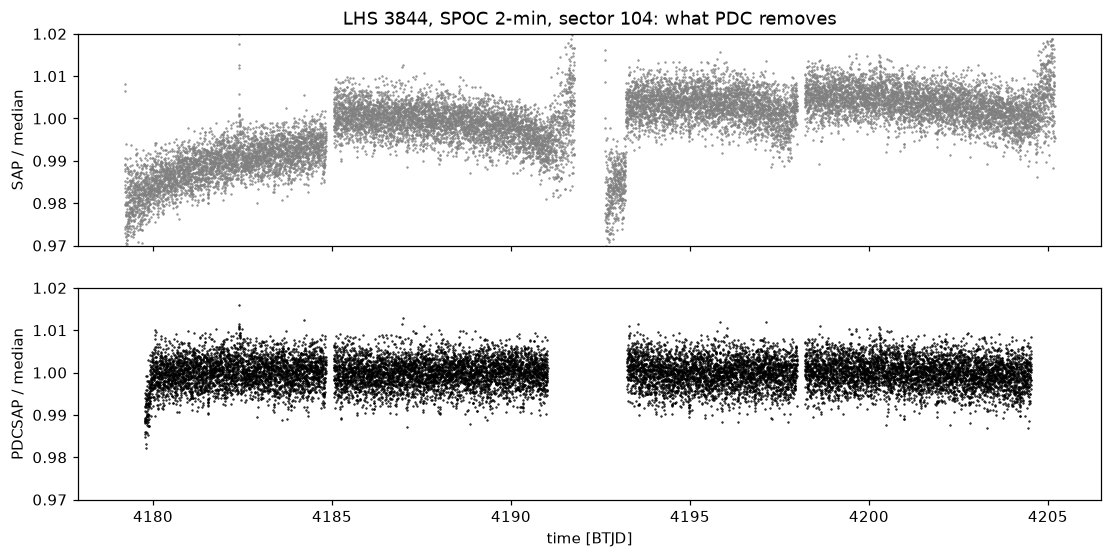

In [8]:
print("flux column used:", lc_spoc.meta["FLUX_ORIGIN"], "| columns:", lc_spoc.colnames)
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(lc_spoc.time.value, lc_spoc.sap_flux.value / np.nanmedian(lc_spoc.sap_flux.value), ".", ms=1, color="0.5")
axes[0].set_ylabel("SAP / median")
axes[1].plot(lc_spoc.time.value, lc_spoc.flux.value / np.nanmedian(lc_spoc.flux.value), ".", ms=1, color="k")
axes[1].set_ylabel("PDCSAP / median"); axes[1].set_xlabel("time [BTJD]")
for ax in axes:
    ax.set_ylim(0.97, 1.02)
axes[0].set_title(f"LHS 3844, SPOC 2-min, sector {SECTOR}: what PDC removes");

The SAP flux shows the instrumental trends (ramps at the start of each orbit,
drifts, jumps between segments); PDCSAP removes most of them, and sets the
worst stretches to NaN (the start of the second orbit, ~4193). It does not
remove everything: a ~1 % ramp is left at the very start of the sector, which
is why the detrending step trims orbit edges. The planet's ~4 000 ppm transits every
11 hours are in both — invisible by eye at this noise level; the detrending
and search notebooks recover them.

## 5. Quality flags

Each cadence has an integer `QUALITY`; each bit of it is one flag. For SPOC:

In [9]:
flags = lk.utils.TessQualityFlags
pd.DataFrame(
    [(bit, value, name, bool(flags.DEFAULT_BITMASK & value), bool(flags.HARD_BITMASK & value))
     for bit, (value, name) in enumerate(flags.STRINGS.items(), start=1)],
    columns=["bit", "value", "meaning", "in 'default'", "in 'hard'"],
).set_index("bit")

,value,meaning,in 'default',in 'hard'
bit,,,,
1,1,Attitude tweak,True,True
2,2,Safe mode,True,True
3,4,Coarse point,True,True
4,8,Earth point,True,True
5,16,Argabrightening,True,True
6,32,Desaturation event,True,True
7,64,Cosmic ray in optimal aperture,False,True
8,128,Manual exclude,True,True
9,256,Discontinuity corrected,False,False


A **bitmask** is the set of bits you reject: a cadence is dropped when
`QUALITY & bitmask != 0`. lightkurve offers `"none"`, `"default"` (the clearly
bad cadences: safe mode, coarse point, Earth point, desaturation events,
manual excludes, ...), `"hard"` (adds e.g. scattered light flags) and
`"hardest"` (every bit). What each costs on our file:

In [10]:
raw = lk.read(path, quality_bitmask="none")
q = raw.quality.value
for mask in ("none", "default", "hard", "hardest"):
    bits = flags.create_quality_mask(q, bitmask=mask)  # True = keep
    n_keep = int(bits.sum())
    print(f"{mask:8s}: keep {n_keep:6d} of {len(q)} cadences ({100 * n_keep / len(q):5.1f} %)")

print("\nflags present in this file:")
for value, count in zip(*np.unique(q[q > 0], return_counts=True)):
    print(f"  {value:6d} x {count:5d}: {', '.join(flags.decode(value))}")

none    : keep  18714 of 18714 cadences (100.0 %)
default : keep  17685 of 18714 cadences ( 94.5 %)
hard    : keep  15902 of 18714 cadences ( 85.0 %)
hardest : keep  15896 of 18714 cadences ( 84.9 %)

flags present in this file:
      16 x    35: Argabrightening
      32 x     6: Desaturation event
     128 x    97: Manual exclude
     160 x     2: Desaturation event, Manual exclude
    4096 x  1783: Straylight2
   16384 x   880: Bad Calibration Exclude
   16400 x     1: Argabrightening, Bad Calibration Exclude
   16416 x     6: Desaturation event, Bad Calibration Exclude
   16544 x     1: Desaturation event, Manual exclude, Bad Calibration Exclude
   16552 x     1: Earth point, Desaturation event, Manual exclude, Bad Calibration Exclude
   32768 x     6: Insufficient Targets for Error Correction Exclude


`"default"` is the right choice for SPOC: it removes the truly bad cadences and
keeps those with soft flags (e.g. scattered light), which are usually fine and
which the detrending step handles. Here `"hard"` would throw away another 10 %
of the data (~2.5 days, mostly the "Straylight2" flag).

**QLP is different.** It uses its own bit assignments; in recent sectors it
marks bad cadences with **bit 31 (value 2³⁰ = 1 073 741 824)**, which is not in
lightkurve's TESS bitmasks. With `"default"`, those cadences survive:

QUALITY values after the 'default' bitmask: {np.int32(0): np.int64(8794), np.int32(1073741824): np.int64(1275), np.int32(1073743872): np.int64(1147)}


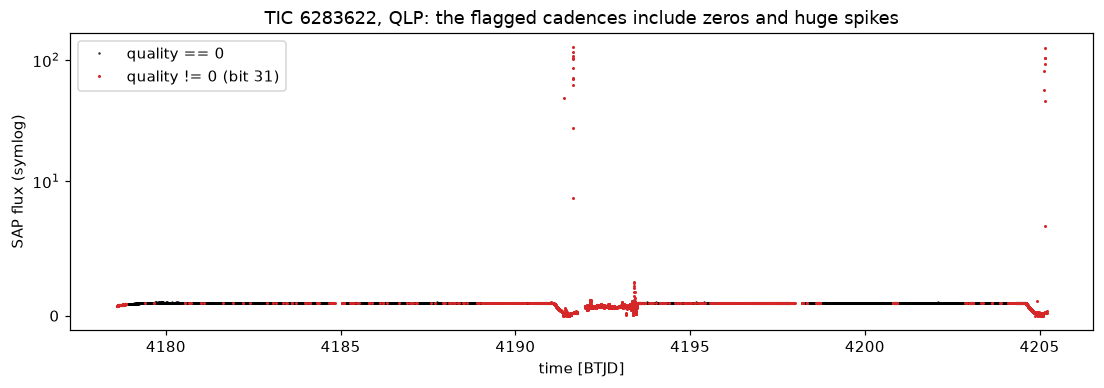

In [11]:
lc_qlp = pick_best(sr_faint).download(download_dir=str(DOWNLOAD_DIR), quality_bitmask="default")
qq = lc_qlp.quality.value
print("QUALITY values after the 'default' bitmask:", dict(zip(*np.unique(qq, return_counts=True))))
bad = qq != 0
fig, ax = plt.subplots()
ax.plot(lc_qlp.time.value[~bad], lc_qlp.flux.value[~bad], ".", ms=1, color="k", label="quality == 0")
ax.plot(lc_qlp.time.value[bad], lc_qlp.flux.value[bad], ".", ms=2, color="C3", label="quality != 0 (bit 31)")
ax.set_yscale("symlog", linthresh=10); ax.legend(); ax.set_xlabel("time [BTJD]"); ax.set_ylabel("SAP flux (symlog)")
ax.set_title(f"TIC {FAINT}, QLP: the flagged cadences include zeros and huge spikes");

So, for QLP, keep only `quality == 0` when *reading* the file (the detrending
step does this). The download itself doesn't need to change: the file on disk
always contains every cadence; the bitmask only acts when the file is read.

## 6. The same star, three products

LHS 3844 has three light curves in this sector. Download all three and compare
them the way a transit search would: the noise, and how the planet's transit
looks when folded on its known period (0.46292913 d).

In [12]:
lcs = {}
for i in range(len(sr)):  # SPOC 20 s, SPOC 2 min, QLP 200 s
    row = sr[i]
    key = f"{row.author[0]} {int(row.exptime[0].value)} s"
    lc = row.download(download_dir=str(DOWNLOAD_DIR), quality_bitmask="default")
    if row.author[0] == "QLP":
        lc = lc[lc.quality.value == 0]
    lcs[key] = lc.remove_nans().normalize()
    print(f"{key:13s} {len(lcs[key]):7d} cadences, flux column = {lc.meta['FLUX_ORIGIN']}, "
          f"file {Path(lc.meta['FILENAME']).stat().st_size / 1e6:5.1f} MB")

SPOC 20 s       95559 cadences, flux column = pdcsap_flux, file  11.5 MB
SPOC 120 s      15896 cadences, flux column = pdcsap_flux, file   1.9 MB
QLP 200 s        8836 cadences, flux column = sap_flux, file   0.7 MB


To compare noise fairly across cadences, bin each light curve to 1 hour: the
scatter of 1-hour bins is what matters for a ~1-hour transit. For white noise
it scales as $\sigma_{1\text{h}} = \sigma_\text{point} / \sqrt{N_\text{points per hour}}$.
We first remove slow trends with a simple running median (12 h), so we measure
noise, not stellar variability.

In [13]:
def robust_std(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))


P_B = 0.46292913
rows = []
for key, lc in lcs.items():
    flat = lc.flatten(window_length=int(0.5 / np.median(np.diff(lc.time.value))) | 1).flux.value
    dt = np.median(np.diff(lc.time.value)) * 86400
    n_per_hour = 3600 / dt
    hourly = pd.Series(flat).groupby((lc.time.value * 24).astype(int)).mean()
    rows.append({
        "product": key,
        "cadence [s]": round(dt),
        "points": len(lc),
        "per-point scatter [ppm]": robust_std(flat) * 1e6,
        "expected 1-h scatter [ppm]": robust_std(flat) * 1e6 / np.sqrt(n_per_hour),
        "measured 1-h scatter [ppm]": robust_std(hourly.values) * 1e6,
    })
pd.DataFrame(rows).set_index("product").astype(float).round(0)

,cadence [s],points,per-point scatter [ppm],expected 1-h scatter [ppm],measured 1-h scatter [ppm]
product,,,,,
SPOC 20 s,20.0,95559.0,8004.0,597.0,697.0
SPOC 120 s,120.0,15896.0,3357.0,613.0,704.0
QLP 200 s,200.0,8836.0,2172.0,512.0,623.0


Per point, the 20-s data are ~√6 ≈ 2.4× noisier than the 2-min data, as
expected for 6× shorter exposures, but per hour all three products are within
~15 % of each other — the photons are the same photons. The differences that
remain come from the pipelines: aperture size, background estimate,
systematics correction (here QLP comes out slightly lower; a larger aperture
collects more of the star but also more of its neighbours, so lower noise is
not automatically better). The measured 1-hour scatter is a bit higher than
the white-noise expectation for all of them: real light curves have some
*correlated* ("red") noise that does not average down. Now the transit:

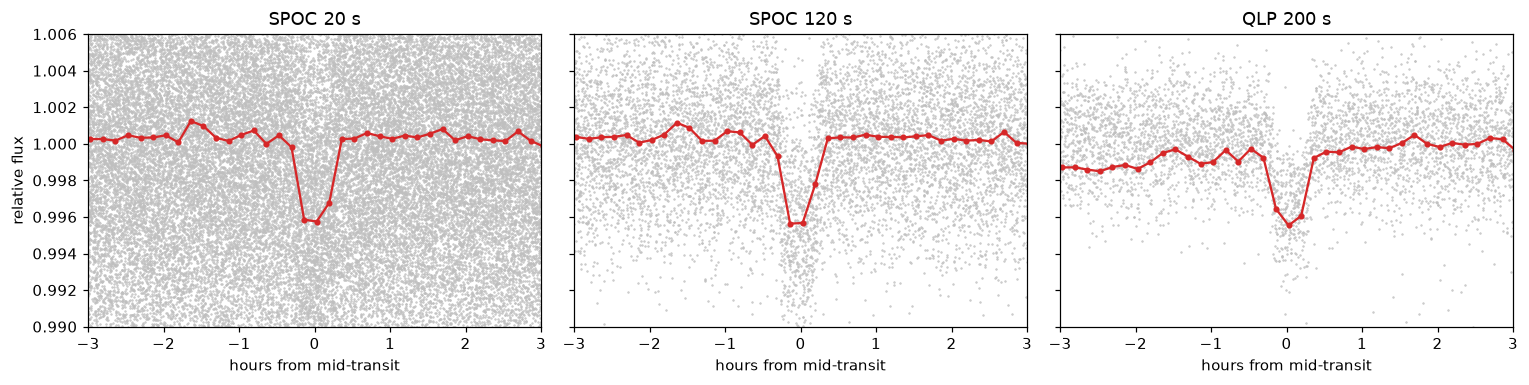

In [14]:
fig, axes = plt.subplots(1, len(lcs), figsize=(14, 3.6), sharey=True)
for ax, (key, lc) in zip(axes, lcs.items()):
    folded = lc.flatten(window_length=int(0.5 / np.median(np.diff(lc.time.value))) | 1).fold(period=P_B)
    ph = folded.phase.value * 24  # hours from an arbitrary epoch
    y = folded.flux.value
    # bin in 10-minute phase bins and centre on the lowest bin
    bins = np.arange(-P_B * 12, P_B * 12 + 1e-9, 1 / 6)
    idx = np.digitize(ph, bins)
    yb = np.array([np.mean(y[idx == j]) if np.any(idx == j) else np.nan for j in range(1, len(bins))])
    shift = (bins[:-1] + 1 / 12)[np.nanargmin(yb)]
    ph_c = ((ph - shift + P_B * 12) % (P_B * 24)) - P_B * 12
    ax.plot(ph_c, y, ".", ms=1, color="0.75")
    idx = np.digitize(ph_c, bins)
    yb = np.array([np.mean(y[idx == j]) if np.any(idx == j) else np.nan for j in range(1, len(bins))])
    ax.plot(bins[:-1] + 1 / 12, yb, "o-", ms=3, color="C3")
    ax.set_title(key); ax.set_xlabel("hours from mid-transit"); ax.set_xlim(-3, 3); ax.set_ylim(0.99, 1.006)
axes[0].set_ylabel("relative flux")
plt.tight_layout()

All three show the ~4 000 ppm, ~30-minute transit. For this star any product
would do. The choice matters at the margins: shallow transits on faint stars,
where the PDC systematics correction and real error bars of SPOC help; and
recent sectors, where only SPOC and QLP exist.

## 7. Other ways to get the data

lightkurve is a convenient wrapper around MAST's API. Other routes:

- **`astroquery.mast.Observations`** — the general MAST interface that
  lightkurve uses underneath: `Observations.query_criteria(...)`,
  `get_product_list(...)`, `download_products(...)`. More control (any product
  type, e.g. data-validation reports), more code.
- **Bulk download scripts** — MAST publishes one shell script per sector with a
  `curl` line per file (archive.stsci.edu/tess/bulk_downloads.html, and per-HLSP
  pages for QLP / TESS-SPOC). For *whole sectors*, downloading everything and
  filtering by TIC ID locally is faster than thousands of searches.
- **Cloud copies** — TESS data are mirrored in a public Amazon S3 bucket
  (`stpubdata`); `Observations.enable_cloud_dataset()` makes astroquery fetch
  from there, which is fast when you compute in the same cloud region.
- **TESScut** (`lk.search_tesscut`) — cut a small image stack out of the
  full-frame images for any position, and do your own photometry. Needed for
  stars that no pipeline covers, or to inspect pixels during vetting.

The query that `lk.search_lightcurve` does, with astroquery directly:

In [15]:
from astroquery.mast import Observations

obs = Observations.query_criteria(target_name=str(LHS3844), obs_collection=["TESS", "HLSP"],
                                  dataproduct_type="timeseries", sequence_number=SECTOR)
obs.to_pandas()[["obs_collection", "provenance_name", "target_name", "sequence_number", "t_exptime", "obs_id"]]

,obs_collection,provenance_name,target_name,sequence_number,t_exptime,obs_id
0,TESS,SPOC,410153553,104,20.0,tess2026137223500-s0104-0000000410153553-0306-...
1,TESS,SPOC,410153553,104,120.0,tess2026137223500-s0104-0000000410153553-0306-s
2,HLSP,QLP,410153553,104,200.0,hlsp_qlp_tess_ffi_s0104-0000000410153553_tess_...


## 8. Doing it for thousands of stars

Downloading one light curve takes a few seconds, mostly waiting for MAST. For
a sector's worth of targets (thousands of stars), four things change:

1. **Parallelism, but gently.** The work is network-bound, so a few parallel
   workers help — but MAST rate-limits clients; with more than ~4 concurrent
   workers you mostly get errors.
2. **Retries.** Timeouts and HTTP errors are routine. Retry each star a few
   times with an increasing wait (*back-off*) before giving up.
3. **A manifest.** Record one row per star: which product was chosen, cadence,
   number of points, the local file path, and a **status** — `ok`, `not_found`
   (the archive has no light curve: the star landed in a CCD gap, or is too
   faint for any pipeline), or `error` (gave up after retries). Downstream steps
   read the manifest, not the directory.
4. **Resume.** Re-running should skip the stars already `ok` or `not_found` and
   retry only errors and new stars, so an interrupted run costs nothing.

Here is that logic for a single star, applied to the three stars above
sequentially.

In [16]:
def fetch_one(tic_id: int, sector: int, n_retries: int = 3) -> dict:
    """Search, pick the best product, download it, describe it. Never raises."""
    row = {"tic_id": tic_id, "author": "", "cadence_s": np.nan, "n_points": 0, "file_path": "", "status": "error", "error": ""}
    for attempt in range(1, n_retries + 1):
        try:
            sr = lk.search_lightcurve(f"TIC {tic_id}", sector=sector, author=AUTHORS)
            best = pick_best(sr)
            if best is None:
                row["status"] = "not_found"
                return row
            lc = best.download(download_dir=str(DOWNLOAD_DIR), quality_bitmask="default")
            if lc is None:
                raise RuntimeError("download returned None")  # corrupt or unavailable file
            row.update(author=best.author[0], cadence_s=float(best.exptime[0].value),
                       n_points=len(lc.remove_nans()), file_path=lc.meta["FILENAME"], status="ok", error="")
            return row
        except Exception as e:  # network/MAST hiccup: wait longer each time, then retry
            row["error"] = f"{type(e).__name__}: {e}"
            time.sleep(2 * attempt)
    return row


manifest = pd.DataFrame([fetch_one(t, SECTOR) for t in (LHS3844, FAINT, EDGE)])
manifest

,tic_id,author,cadence_s,n_points,file_path,status,error
0,410153553,SPOC,120.0,15896,../data/walkthrough_downloads/mastDownload/TES...,ok,
1,6283622,QLP,200.0,11094,../data/walkthrough_downloads/mastDownload/HLS...,ok,
2,165941376,,NaN,0,,not_found,


In a real run, the loop over stars goes through a small worker pool (e.g.
`joblib.Parallel(n_jobs=4)`), the manifest is saved after each run and merged
with the previous one, and a final count of `ok / not_found / error` tells you
whether the run is complete (expect most stars `ok`; a few percent
`not_found`; errors should go to zero after a re-run).

### Summary — the recipe

1. For each star: `lk.search_lightcurve(f"TIC {tic}", sector=N, author=["SPOC", "TESS-SPOC", "QLP"])`.
2. Pick one product by a fixed preference: SPOC 2 min → SPOC 20 s → TESS-SPOC → QLP.
3. `download(download_dir=..., quality_bitmask="default")`; keep the original FITS
   file (it has everything; later steps decide what to use).
4. Write a manifest row per star with the status; retry errors with back-off;
   ≤ 4 parallel workers; skip stars already done.
5. Remember for the next step: SPOC → `PDCSAP_FLUX` with errors; QLP →
   `SAP_FLUX` without errors and with bit-31 flags that must be removed by
   keeping `quality == 0`.

**References**: lightkurve documentation and tutorials
(lightkurve.github.io/lightkurve); TESS Science Data Products Description
Document (SPOC file formats and quality flags) and the per-sector Data Release
Notes (archive.stsci.edu/tess); Jenkins et al. 2016 (SPOC); Huang et al. 2020
and Kunimoto et al. 2021/2022 (QLP); Caldwell et al. 2020 (TESS-SPOC); MAST
TESS bulk downloads (archive.stsci.edu/tess/bulk_downloads.html).